In [5]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [24]:
@dataclass(frozen=True)
class RmmLeadCurveConfig:
    data_dir: str
    period: str = "2012-2013"
    exp_list: tuple[str, ...] = ("CTRL","DARTOP","ERA5OP","ERA5DL","ERA5BL","DARTBL","DARTBA","DARTAE")
    obs_file: str | None = None          # if None, auto: rmm_obs_projected_{period}.nc
    amp_thresh: float = 1.0              # apply to OBS amplitude
    window_days: int = 60                # running window length
    min_samples: int = 30                # min paired days per window
    max_lead_days: int | None = None     # optional truncate lead range

@dataclass(frozen=True)
class LeadBinSpec:
    name: str
    start: int  # inclusive
    end: int    # inclusive

DEFAULT_LEAD_BINS = (
    LeadBinSpec("Wk1-2 (1-14)", 1, 14),
    LeadBinSpec("Wk3-4 (15-28)", 15, 28),
    LeadBinSpec("Wk5-6 (29-42)", 29, 42),
    LeadBinSpec("Wk7-8 (43-56)", 43, 56),
)

class RmmDiagnostics:
    def __init__(self, cfg: RmmLeadCurveConfig, *, verbose: bool = True):
        self.cfg = cfg
        self.verbose = verbose
        self._obs = self._open_obs()

    def _log(self, msg: str):
        if self.verbose:
            print(f"[RMM-DIAG] {msg}")

    def _open_obs(self) -> xr.Dataset:
        cfg = self.cfg
        data_dir = Path(cfg.data_dir)
        obs_path = Path(cfg.obs_file) if cfg.obs_file else (data_dir / f"rmm_obs_projected_{cfg.period}.nc")
        ds = xr.open_dataset(obs_path)

        if "time" not in ds.coords:
            raise KeyError(f"OBS file missing coord 'time': {obs_path}")
        for v in ("RMM1_obs", "RMM2_obs", "RMM_amp_obs"):
            if v not in ds:
                raise KeyError(f"OBS file missing variable '{v}': {obs_path}")

        ds = ds.sortby("time")
        self._log(f"Loaded OBS: {obs_path.name}  n={ds.sizes['time']}")
        return ds

    def _open_fcst(self, exp: str) -> xr.Dataset:
        cfg = self.cfg
        p = Path(cfg.data_dir) / f"rmm_fcst_projected_{exp}_{cfg.period}.nc"
        ds = xr.open_dataset(p)

        # If some file is (init,time), squeeze
        if "time" not in ds.coords:
            if "init" in ds.dims and "time" in ds.dims and ds.sizes["init"] == 1:
                ds = ds.isel(init=0, drop=True)
            else:
                raise KeyError(f"{exp} file missing coord 'time': {p}")

        for v in ("RMM1_fcst", "RMM2_fcst"):
            if v not in ds:
                raise KeyError(f"{exp} file missing variable '{v}': {p}")

        return ds.sortby("time")

    # -----------------------------
    # metrics
    # -----------------------------
    @staticmethod
    def _vector_acc(r1f, r2f, r1o, r2o) -> float:
        # remove mean (correlation-style)
        r1f = r1f - np.nanmean(r1f); r2f = r2f - np.nanmean(r2f)
        r1o = r1o - np.nanmean(r1o); r2o = r2o - np.nanmean(r2o)

        num = np.nansum(r1f * r1o + r2f * r2o)
        den = np.sqrt(np.nansum(r1f * r1f + r2f * r2f) * np.nansum(r1o * r1o + r2o * r2o))
        if not np.isfinite(den) or den == 0:
            return np.nan
        return float(num / den)

    @staticmethod
    def _vector_rmse(r1f, r2f, r1o, r2o) -> float:
        e1 = r1f - r1o
        e2 = r2f - r2o
        # RMSE of vector magnitude error
        return float(np.sqrt(np.nanmean(e1 * e1 + e2 * e2)))

    # -----------------------------
    # shared alignment + masking
    # -----------------------------
    def _aligned_pair(self, exp: str) -> tuple[xr.Dataset, xr.Dataset]:
        cfg = self.cfg
        fc = self._open_fcst(exp)
        obs = self._obs

        t = np.intersect1d(fc["time"].values, obs["time"].values)
        if t.size < cfg.min_samples:
            raise ValueError(f"{exp}: too few common days with OBS after alignment: {t.size}")

        fc = fc.sel(time=t)
        obs = obs.sel(time=t)

        if cfg.amp_thresh is not None:
            m = (obs["RMM_amp_obs"].values >= float(cfg.amp_thresh))
            fc = fc.isel(time=m)
            obs = obs.isel(time=m)

        if obs.sizes["time"] < cfg.min_samples:
            raise ValueError(f"{exp}: too few samples after amp_thresh: n={obs.sizes['time']}")

        return fc, obs
    
    def compute_running_curves(self, exp: str) -> xr.Dataset:
        """
        Running (forward-window) ACC/RMSE curves versus lead day.
    
        Key choices (paper-friendly):
          - Align forecast and obs by common valid_time
          - Apply amplitude threshold using OBS amplitude (amp_thresh)
          - Define lead_day relative to first valid time in the *aligned* series
          - Use FORWARD running window: [L, L+window_days), not centered
        """
        cfg = self.cfg
    
        fc = self._open_fcst(exp)    # rmm_fcst_projected_<exp>_<period>.nc
        obs = self._obs              # cached obs opened in __init__
    
        # ---------------------------
        # 1) get 1D forecast time series (squeeze init if present)
        # ---------------------------
        if "init" in fc["RMM1_fcst"].dims:
            if fc.sizes.get("init", 0) != 1:
                raise ValueError(f"{exp}: expected init size=1, got {fc.sizes.get('init')}")
            r1f = fc["RMM1_fcst"].isel(init=0, drop=True)
            r2f = fc["RMM2_fcst"].isel(init=0, drop=True)
            af  = fc["RMM_amp_fcst"].isel(init=0, drop=True) if "RMM_amp_fcst" in fc else None
    
            if "valid_time" in fc:
                tf = fc["valid_time"].isel(init=0, drop=True) if ("init" in fc["valid_time"].dims) else fc["valid_time"]
            else:
                tf = r1f["time"]
        else:
            r1f = fc["RMM1_fcst"]
            r2f = fc["RMM2_fcst"]
            af  = fc["RMM_amp_fcst"] if "RMM_amp_fcst" in fc else None
            tf  = fc["valid_time"] if "valid_time" in fc else r1f["time"]
    
        # obs (already 1D)
        r1o = obs["RMM1_obs"]
        r2o = obs["RMM2_obs"]
        ao  = obs["RMM_amp_obs"]
        to  = obs["valid_time"] if "valid_time" in obs else obs["time"]
    
        # ---------------------------
        # 2) align by common valid_time
        # ---------------------------
        t_common = np.intersect1d(np.asarray(tf.values), np.asarray(to.values))
        if t_common.size < cfg.min_samples:
            raise ValueError(f"{exp}: too few common days after time alignment: {t_common.size}")
    
        # IMPORTANT: select by *time coordinate* (not by valid_time array name)
        # Here r1f/r2f are indexed by "time"; tf is a coord/data that matches that "time".
        # We assume r1f.time values are the valid times used in tf (as produced by the projector).
        r1f = r1f.sel(time=t_common)
        r2f = r2f.sel(time=t_common)
        if af is not None:
            af = af.sel(time=t_common)
    
        r1o = r1o.sel(time=t_common)
        r2o = r2o.sel(time=t_common)
        ao  = ao.sel(time=t_common)
    
        # ---------------------------
        # 3) amplitude threshold using OBS amp
        # ---------------------------
        if cfg.amp_thresh is not None:
            keep = (ao >= float(cfg.amp_thresh))
            r1f = r1f.where(keep, drop=True)
            r2f = r2f.where(keep, drop=True)
            r1o = r1o.where(keep, drop=True)
            r2o = r2o.where(keep, drop=True)
            # (af not used for metrics; ignore)
    
        n = int(r1f.sizes["time"])
        if n < cfg.min_samples:
            raise ValueError(f"{exp}: too few samples after amp_thresh: n={n}")
    
        # ---------------------------
        # 4) lead day: days since first retained valid time
        # ---------------------------
        tvals = r1f["time"].values.astype("datetime64[D]")
        lead = (tvals - tvals[0]).astype("timedelta64[D]").astype(int)
    
        # choose max lead
        max_lead = int(cfg.max_lead_days) if (cfg.max_lead_days is not None) else int(np.nanmax(lead))
    
        # ---------------------------
        # 5) forward running window skill: [L, L+window_days)
        # ---------------------------
        win = int(cfg.window_days)
        acc_vals  = np.full(max_lead + 1, np.nan, dtype=float)
        rmse_vals = np.full(max_lead + 1, np.nan, dtype=float)
    
        r1f_np = np.asarray(r1f.values, dtype=float).reshape(-1)
        r2f_np = np.asarray(r2f.values, dtype=float).reshape(-1)
        r1o_np = np.asarray(r1o.values, dtype=float).reshape(-1)
        r2o_np = np.asarray(r2o.values, dtype=float).reshape(-1)
    
        for L in range(0, max_lead + 1):
            m = np.where((lead >= L) & (lead < L + win))[0]
            if m.size < cfg.min_samples:
                continue
            acc_vals[L]  = self._vector_acc(r1f_np[m], r2f_np[m], r1o_np[m], r2o_np[m])
            rmse_vals[L] = self._vector_rmse(r1f_np[m], r2f_np[m], r1o_np[m], r2o_np[m])
    
        return xr.Dataset(
            {"ACC_VEC": (("lead_day",), acc_vals),
             "RMSE_VEC": (("lead_day",), rmse_vals)},
            coords={"lead_day": np.arange(max_lead + 1, dtype=int)},
            attrs={
                "exp": exp,
                "period": cfg.period,
                "amp_thresh": float(cfg.amp_thresh) if (cfg.amp_thresh is not None) else np.nan,
                "window_days": int(cfg.window_days),
                "min_samples": int(cfg.min_samples),
                "window_type": "forward",
            },
        )


    # -----------------------------
    # plotting
    # -----------------------------
    def plot_lead_acc_rmse_all(
        self,
        *,
        title: str | None = None,
        show: bool = True,
        out_png: str | None = None,
        acc_refline: float | None = 0.5,
    ):
        cfg = self.cfg

        fig, axes = plt.subplots(2, 1, figsize=(10.8, 6.4), sharex=True)

        for exp in cfg.exp_list:
            ds = self.compute_running_curves(exp)
            x = ds["lead_day"].values
            axes[0].plot(x, ds["ACC_VEC"].values, label=exp)
            axes[1].plot(x, ds["RMSE_VEC"].values, label=exp)

        if acc_refline is not None:
            axes[0].axhline(float(acc_refline), linewidth=1.0)

        axes[0].set_ylabel("ACC_VEC (running window)")
        axes[0].set_ylim(-1.0, 1.0)

        axes[1].set_ylabel("RMSE_VEC (running window)")
        axes[1].set_xlabel("Forecast lead day (days since first valid time)")

        if title is None:
            title = f"MJO RMM running skill ({cfg.period})  amp≥{cfg.amp_thresh}  win={cfg.window_days}d"
        axes[0].set_title(title)

        # one legend (top panel)
        axes[0].legend(ncol=2, frameon=False, loc="upper right")

        plt.tight_layout()

        if out_png:
            out_png = str(out_png)
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            plt.savefig(out_png, dpi=200)

        if show:
            plt.show()
        else:
            plt.close(fig)

    def _get_1d_fcst_obs_aligned(self, exp: str):
        """
        Return 1D numpy arrays after:
          - squeezing init if present (init size=1)
          - aligning by common time (valid_time preferred)
          - applying OBS amplitude threshold (if set)
        """
        cfg = self.cfg
        fc = self._open_fcst(exp)
        obs = self._obs

        # forecast squeeze init if needed
        if "init" in fc["RMM1_fcst"].dims:
            if fc.sizes.get("init", 0) != 1:
                raise ValueError(f"{exp}: expected init size=1, got {fc.sizes.get('init')}")
            r1f = fc["RMM1_fcst"].isel(init=0, drop=True)
            r2f = fc["RMM2_fcst"].isel(init=0, drop=True)
            tf  = (fc["valid_time"].isel(init=0, drop=True)
                   if ("valid_time" in fc and "init" in fc["valid_time"].dims)
                   else (fc["valid_time"] if "valid_time" in fc else r1f["time"]))
        else:
            r1f = fc["RMM1_fcst"]
            r2f = fc["RMM2_fcst"]
            tf  = fc["valid_time"] if "valid_time" in fc else r1f["time"]

        # obs
        r1o = obs["RMM1_obs"]
        r2o = obs["RMM2_obs"]
        ao  = obs["RMM_amp_obs"]
        to  = obs["valid_time"] if "valid_time" in obs else obs["time"]

        # align times (common valid times)
        t_common = np.intersect1d(np.asarray(tf.values), np.asarray(to.values))
        if t_common.size < cfg.min_samples:
            raise ValueError(f"{exp}: too few common days after alignment: {t_common.size}")

        # select along 'time' (these datasets are indexed by time)
        r1f = r1f.sel(time=t_common)
        r2f = r2f.sel(time=t_common)
        r1o = r1o.sel(time=t_common)
        r2o = r2o.sel(time=t_common)
        ao  = ao .sel(time=t_common)

        # amp threshold on OBS amp
        if cfg.amp_thresh is not None:
            keep = (ao >= float(cfg.amp_thresh))
            r1f = r1f.where(keep, drop=True)
            r2f = r2f.where(keep, drop=True)
            r1o = r1o.where(keep, drop=True)
            r2o = r2o.where(keep, drop=True)

        n = int(r1f.sizes["time"])
        if n < cfg.min_samples:
            raise ValueError(f"{exp}: too few samples after amp_thresh: n={n}")

        # lead day since first retained day
        tvals = r1f["time"].values.astype("datetime64[D]")
        lead = (tvals - tvals[0]).astype("timedelta64[D]").astype(int)

        # to 1D numpy
        r1f_np = np.asarray(r1f.values, dtype=float).reshape(-1)
        r2f_np = np.asarray(r2f.values, dtype=float).reshape(-1)
        r1o_np = np.asarray(r1o.values, dtype=float).reshape(-1)
        r2o_np = np.asarray(r2o.values, dtype=float).reshape(-1)

        return r1f_np, r2f_np, r1o_np, r2o_np, lead

    def compute_lead_bin_metrics(
        self,
        exp: str,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
    ) -> xr.Dataset:
        cfg = self.cfg
        min_samp = int(require_min_samples) if (require_min_samples is not None) else int(cfg.min_samples)

        r1f, r2f, r1o, r2o, lead = self._get_1d_fcst_obs_aligned(exp)

        names = [b.name for b in bins]
        acc = np.full(len(bins), np.nan, dtype=float)
        rmse = np.full(len(bins), np.nan, dtype=float)
        ns  = np.zeros(len(bins), dtype=int)

        for i, b in enumerate(bins):
            m = np.where((lead >= b.start) & (lead <= b.end))[0]
            ns[i] = int(m.size)
            if m.size < min_samp:
                continue
            acc[i]  = self._vector_acc(r1f[m], r2f[m], r1o[m], r2o[m])
            rmse[i] = self._vector_rmse(r1f[m], r2f[m], r1o[m], r2o[m])

        return xr.Dataset(
            {
                "ACC_VEC": (("lead_bin",), acc),
                "RMSE_VEC": (("lead_bin",), rmse),
                "n_samples": (("lead_bin",), ns),
            },
            coords={"lead_bin": np.asarray(names, dtype="U")},
            attrs={
                "exp": exp,
                "period": cfg.period,
                "amp_thresh": float(cfg.amp_thresh) if (cfg.amp_thresh is not None) else np.nan,
                "min_samples": min_samp,
            },
        )

    def compute_lead_bin_table(
        self,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
    ) -> xr.Dataset:
        cfg = self.cfg
        all_ds = []
        for exp in cfg.exp_list:
            ds = self.compute_lead_bin_metrics(exp, bins=bins, require_min_samples=require_min_samples)
            all_ds.append(ds.expand_dims(exp=[exp]))
        return xr.concat(all_ds, dim="exp")

    def plot_lead_bin_bars(
        self,
        *,
        bins: tuple[LeadBinSpec, ...] = DEFAULT_LEAD_BINS,
        require_min_samples: int | None = None,
        show: bool = True,
        out_png: str | None = None,
        title: str | None = None,
        acc_refline: float | None = 0.5,
        annotate_n: bool = True,
    ):
        cfg = self.cfg
        tab = self.compute_lead_bin_table(bins=bins, require_min_samples=require_min_samples)

        lead_bins = tab["lead_bin"].values.tolist()
        exps = tab["exp"].values.tolist()

        ACC = np.asarray(tab["ACC_VEC"].values, dtype=float)   # [exp, bin]
        RMSE = np.asarray(tab["RMSE_VEC"].values, dtype=float) # [exp, bin]
        NS = np.asarray(tab["n_samples"].values, dtype=int)

        n_exp = len(exps)
        n_bin = len(lead_bins)

        x = np.arange(n_bin)
        width = 0.8 / max(n_exp, 1)

        fig, axes = plt.subplots(2, 1, figsize=(12.8, 7.2), sharex=True)

        for j, exp in enumerate(exps):
            xpos = x - 0.4 + width/2 + j * width
            axes[0].bar(xpos, ACC[j, :], width=width, label=exp)
            axes[1].bar(xpos, RMSE[j, :], width=width, label=exp)

            if annotate_n:
                for k in range(n_bin):
                    if np.isfinite(ACC[j, k]):
                        axes[0].text(xpos[k], ACC[j, k], f"{NS[j,k]}", ha="center", va="bottom", fontsize=8)
                    if np.isfinite(RMSE[j, k]):
                        axes[1].text(xpos[k], RMSE[j, k], f"{NS[j,k]}", ha="center", va="bottom", fontsize=8)

        if acc_refline is not None:
            axes[0].axhline(float(acc_refline), linewidth=1.0)

        axes[0].set_ylabel("Bivariate ACC (RMM vector)")
        axes[0].set_ylim(-1.0, 1.0)

        axes[1].set_ylabel("Bivariate RMSE (RMM vector)")
        axes[1].set_xlabel("Lead bin (days)")

        axes[1].set_xticks(x)
        axes[1].set_xticklabels(lead_bins)

        if title is None:
            title = f"MJO RMM lead-bin skill ({cfg.period})  amp≥{cfg.amp_thresh}"
        axes[0].set_title(title)

        axes[0].legend(ncol=2, frameon=False, loc="upper right")

        plt.tight_layout()

        if out_png:
            out_png = str(out_png)
            Path(out_png).parent.mkdir(parents=True, exist_ok=True)
            plt.savefig(out_png, dpi=200)

        if show:
            plt.show()
        else:
            plt.close(fig)

        return tab
        

[RMM-DIAG] Loaded OBS: rmm_obs_projected_2012-2013.nc  n=730


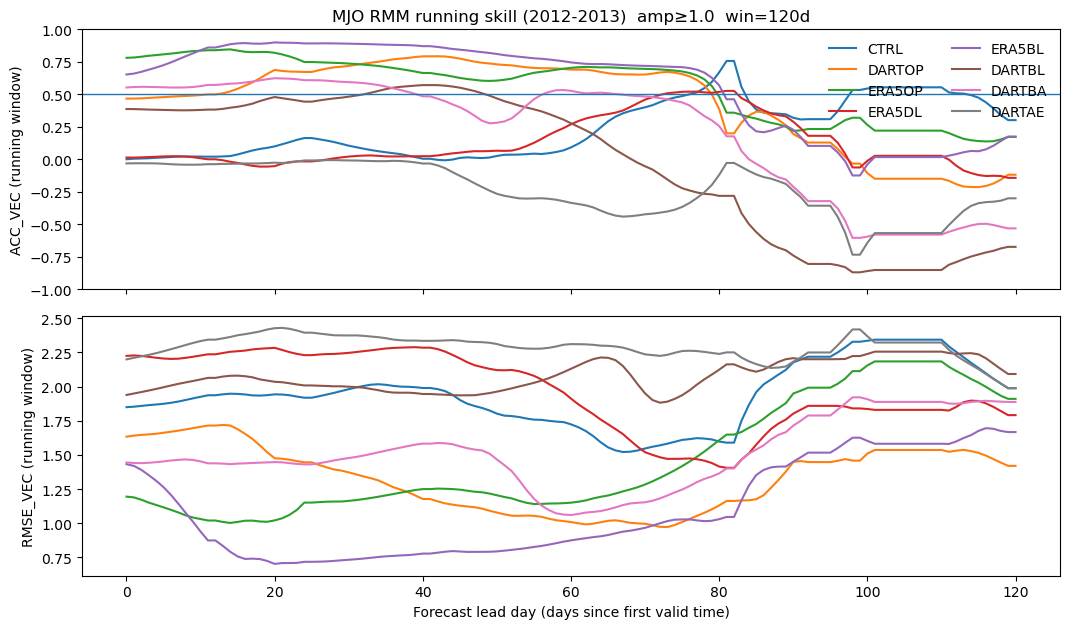

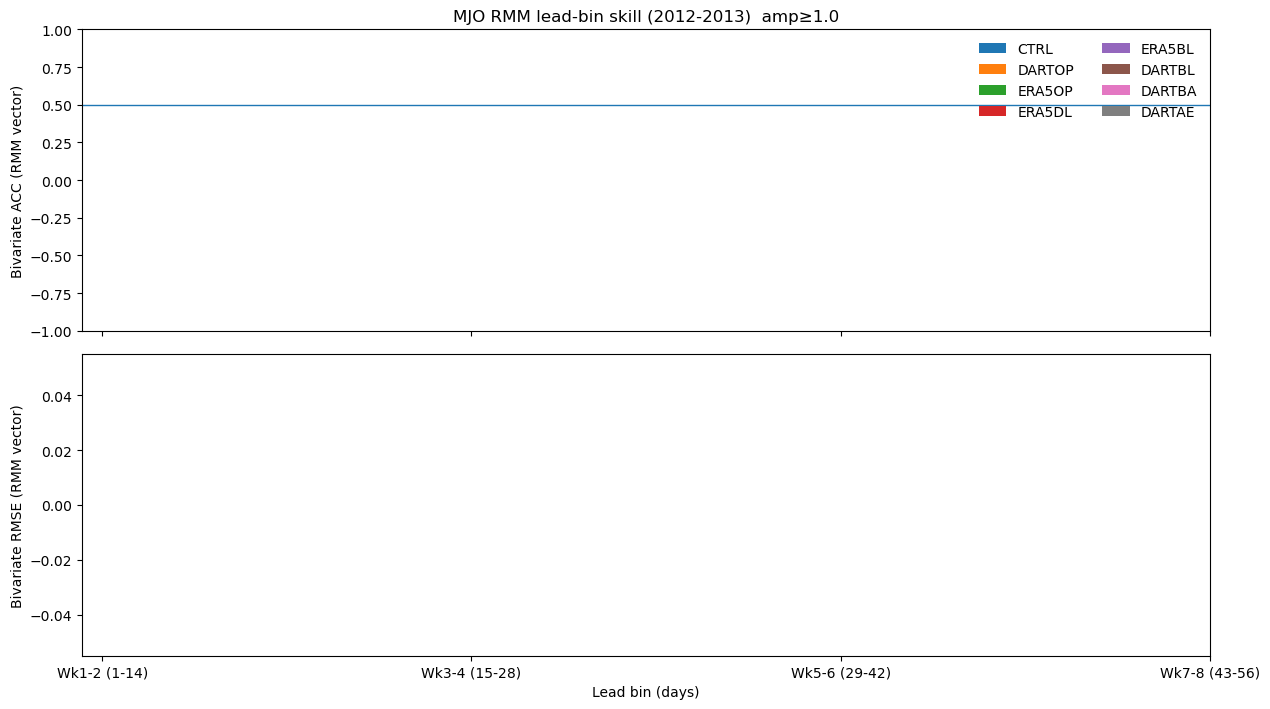

In [25]:
if __name__ == "__main__":
    work_dir = Path("/lcrc/group/e3sm/ac.szhang/acme_scratch/e3sm_project/v3_dart_paper")
    data_dir = f"{work_dir}/figure_data/mjo"   # <-- remove comma
    fig_dir = f"{work_dir}/mjo_analysis"

    period = "2012-2013"
    exp_list = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
    amp_thresh = 1.0
    window_days = 120
    min_samples = 15
    max_lead_days = 120

    cfg = RmmLeadCurveConfig(
        data_dir=data_dir,
        period=period,
        exp_list=exp_list,
        amp_thresh=amp_thresh,
        window_days=window_days,
        min_samples=min_samples,
        max_lead_days=max_lead_days,
    )

    out_png = f"{fig_dir}/rmm_figs/rmm_lead_ACC_RMSE_all.png"  # <-- remove comma
    Path(out_png).parent.mkdir(parents=True, exist_ok=True)

    diag = RmmDiagnostics(cfg, verbose=True)
    diag.plot_lead_acc_rmse_all(
        out_png=out_png,
        show=True,
    )
    
    tab = diag.plot_lead_bin_bars(
        out_png=f"{fig_dir}/rmm_leadbin_ACC_RMSE_bar_{period}.png",
        show=True,
        annotate_n=True,
        acc_refline=0.5,
    )
    tab.to_netcdf(f"{fig_dir}/rmm_leadbin_skill_{period}.nc")
